# Part C

## 4.1 Burnout Level Classification

In [101]:
import pandas as pd
data = pd.read_csv("processed_data.csv")
data_scaled = pd.read_csv("processed_data_scaled.csv")

In [102]:
print(f"Unscaled data: {data.shape}")
print(f"Scaled data: {data_scaled.shape}")

Unscaled data: (15000, 16)
Scaled data: (15000, 16)


In [103]:
print(data['split'].value_counts())

split
train    12000
test      3000
Name: count, dtype: int64


In [104]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from xgboost import XGBClassifier

In [114]:
features = [
    'Age',
    'Daily_Social_Media_Hours',
    'Daily_AI_Tool_Usage_Hours',
    'Sleep_Hours',
    'Physical_Activity_Hours',
    'Mental_Health_Score',
    'Physical_Health_Score',
    'Social_Isolation_Score',
    'Gender_Male',
    'Gender_Non-binary',
    'Education_Level_High School',
    'Education_Level_University',
]
target = 'Burnout_Level'

In [115]:
# Use standardized data for Logistic Regression and keep the Part A split
train_scaled = data_scaled[data_scaled['split'] == 'train']
test_scaled = data_scaled[data_scaled['split'] == 'test']
x_train_scaled = train_scaled[features]
x_test_scaled = test_scaled[features]
y_train_scaled = train_scaled[target]
y_test_scaled = test_scaled[target]
# Use unscaled data for Decision Tree, Random Forest, and XGBoost
train_unscaled = data[data['split'] == 'train']
test_unscaled = data[data['split'] == 'test']
x_train_unscaled = train_unscaled[features]
x_test_unscaled = test_unscaled[features]
y_train_unscaled = train_unscaled[target]
y_test_unscaled = test_unscaled[target]

### Train the four models

In [116]:
# Logistic Regression without class weighting
lr_un = LogisticRegression(solver='lbfgs',random_state=42,max_iter=1000)
lr_un.fit(x_train_scaled,y_train_scaled)
lr_un_pred = lr_un.predict(x_test_scaled)
print(lr_un_pred)
# Logistic Regression with class weighting
lr = LogisticRegression(solver='lbfgs',random_state=42,class_weight='balanced',max_iter=1000)
lr.fit(x_train_scaled,y_train_scaled)
lr_pred = lr.predict(x_test_scaled)
print(lr_pred)

[0 1 1 ... 0 1 1]
[0 1 1 ... 0 1 2]


In [117]:
# Decision Tree without class weighting
dt_un = DecisionTreeClassifier(criterion='entropy',max_depth=5,random_state=42)
dt_un.fit(x_train_unscaled,y_train_unscaled)
dt_un_pred = dt_un.predict(x_test_unscaled)
print(dt_un_pred)
# Decision Tree with class weighting
dt = DecisionTreeClassifier(criterion='entropy',max_depth=5,random_state=42,class_weight='balanced')
dt.fit(x_train_unscaled,y_train_unscaled)
dt_pred = dt.predict(x_test_unscaled)
print(dt_pred)

[0 0 1 ... 0 0 1]
[1 0 1 ... 1 1 2]


In [118]:
# Random Forest without class weighting
rf_un = RandomForestClassifier(n_estimators=100,random_state=42)
rf_un.fit(x_train_unscaled,y_train_unscaled)
rf_un_pred = rf_un.predict(x_test_unscaled)
print(rf_un_pred)
# Random Forest with class weighting
rf = RandomForestClassifier(n_estimators=100,random_state=42,class_weight='balanced')
rf.fit(x_train_unscaled,y_train_unscaled)
rf_pred = rf.predict(x_test_unscaled)
print(rf_pred)

[0 0 1 ... 0 0 1]
[0 1 1 ... 0 1 2]


In [119]:
# XGBoost without class weighting
xgb_un = XGBClassifier(
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)
xgb_un.fit(x_train_unscaled, y_train_unscaled)
xgb_un_pred = xgb_un.predict(x_test_unscaled)
print(xgb_un_pred)
# XGBoost with class weighting
counts = y_train_unscaled.value_counts()
weights = len(y_train_unscaled) / (len(counts) * counts)
xgb_weights = y_train_unscaled.map(weights)
xgb = XGBClassifier(
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)
xgb.fit(x_train_unscaled,y_train_unscaled,sample_weight=xgb_weights)
xgb_pred = xgb.predict(x_test_unscaled)
print(xgb_pred)

[0 0 1 ... 0 1 1]
[0 1 1 ... 0 1 2]


## 5.1 Model Comparison

In [120]:
models = [
    ('Logistic Regression(unweighted)',y_test_scaled,lr_un_pred),
    ('Logistic Regression(weighted)',y_test_scaled,lr_pred),
    ('Decision Tree(unweighted)',y_test_unscaled,dt_un_pred),
    ('Decision Tree(weighted)',y_test_unscaled,dt_pred),
    ('Random Forest(unweighted)',y_test_unscaled,rf_un_pred),
    ('Random Forest(weighted)',y_test_unscaled,rf_pred),
    ('XGBoost(unweighted)',y_test_unscaled,xgb_un_pred),
    ('XGBoost(weighted)',y_test_unscaled,xgb_pred),
]

print(f'{'Model':<37} {'Test Acc':>12} {'Macro F1':>12} ')
print('=' * 64)
for name,y_true,y_pred in models:
    test_accuracy = accuracy_score(y_true,y_pred)
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average = 'macro',
        zero_division = 0
)
    print(f'{name:<37} {test_accuracy:>12.4f} {macro_f1:>12.4f}')

Model                                     Test Acc     Macro F1 
Logistic Regression(unweighted)             0.6997       0.5104
Logistic Regression(weighted)               0.6247       0.4890
Decision Tree(unweighted)                   0.6667       0.4363
Decision Tree(weighted)                     0.5493       0.4319
Random Forest(unweighted)                   0.6857       0.4917
Random Forest(weighted)                     0.6560       0.4987
XGBoost(unweighted)                         0.6760       0.4791
XGBoost(weighted)                           0.6260       0.4804


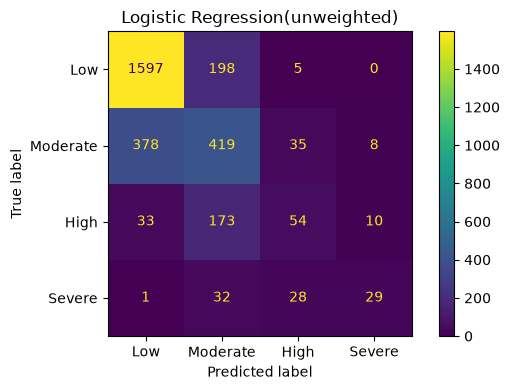

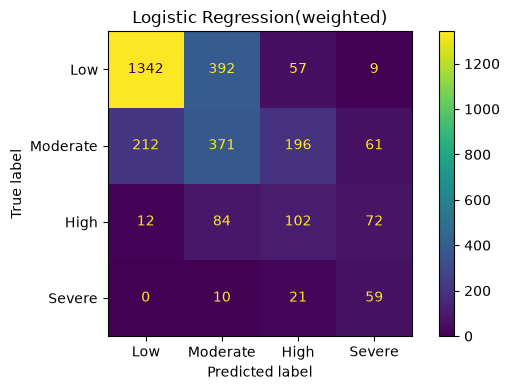

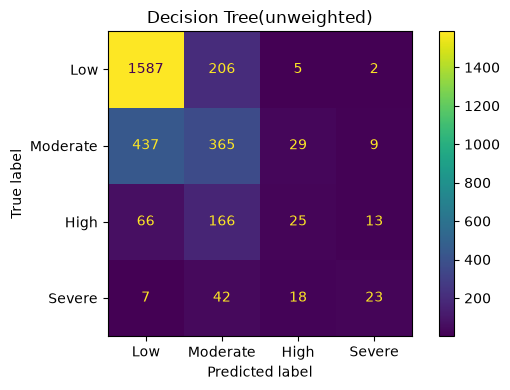

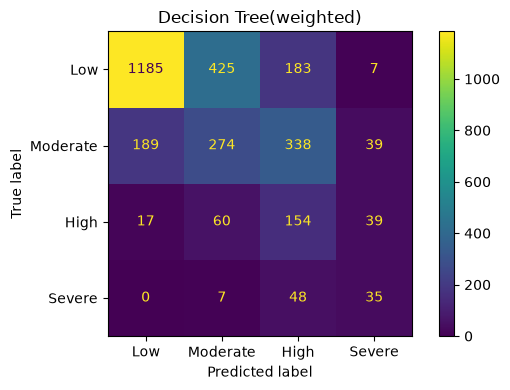

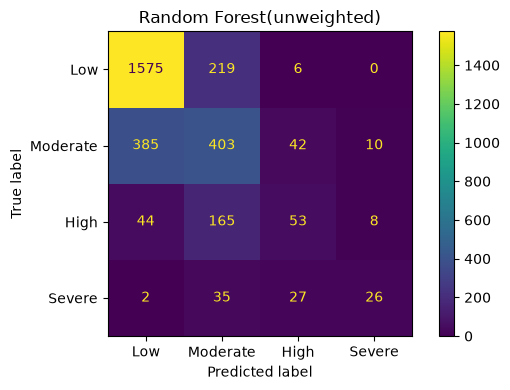

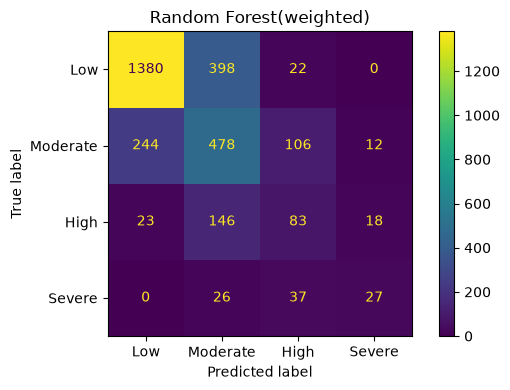

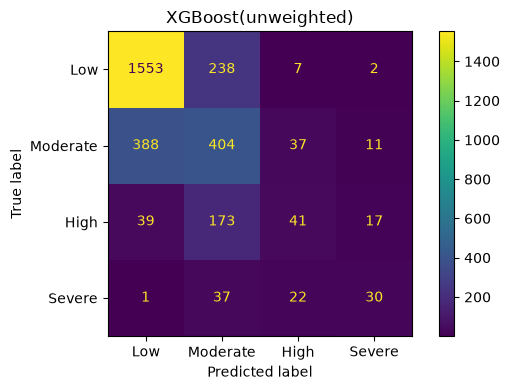

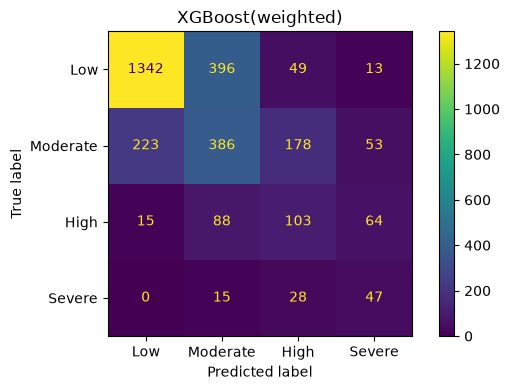

In [121]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
class_labels = ['Low','Moderate','High','Severe']
for name,y_true,y_pred in models:
    fig, axes = plt.subplots(figsize=(6, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=[0,1,2,3],
        display_labels=class_labels,
        ax=axes
    )
    axes.set_title(name)
    plt.tight_layout()
    plt.show()